# PSIB — Análisis del reflejo fotomotor pupilar

Este notebook **solo llama funciones** del paquete `pupila/` y muestra imágenes y resultados.
Toda la lógica está en `pupila/modulo1.py … modulo4.py`, video.py` y `pipeline.py`.

Para procesar otro video: cambiá únicamente `video_path` en `config.yaml` (o corré `python run_pipeline.py --video otro.mov`).

Índice: Configuración y ROI · Módulo 1 · Módulo 2 · Módulo 3 · Módulo 4 · Salida estandarizada (CSV)

In [2]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.insert(0, str(Path.cwd()))      # el notebook vive en la raíz del repositorio

from pupila.config import cargar_config
from pupila.video import preparar_referencia, leer_frame, recortar_roi
from pupila import modulo1 as m1, modulo2 as m2, modulo3 as m3, modulo4 as m4
from pupila.pipeline import ejecutar_pipeline, graficar_curva

cfg = cargar_config("config.yaml")
print("Video:", cfg["video_path"])


def mostrar(imgs, titulos=None, filas=1, figsize=None, cmap="gray", vmin=0, vmax=255):
    """Muestra una grilla de imágenes (RGB o gris). Para imágenes float usar vmin=vmax=None."""
    n = len(imgs)
    cols = int(np.ceil(n / filas))
    fig, axs = plt.subplots(filas, cols, figsize=figsize or (4.5 * cols, 4 * filas), squeeze=False)
    for ax in axs.ravel():
        ax.axis("off")
    for ax, im, t in zip(axs.ravel(), imgs, titulos or [""] * n):
        if im.ndim == 3:
            ax.imshow(im)
        else:
            ax.imshow(im, cmap=cmap, vmin=vmin, vmax=vmax)
        ax.set_title(t, fontsize=10)
    plt.tight_layout()
    plt.show()


def histogramas(imgs, titulos):
    fig, axs = plt.subplots(1, len(imgs), figsize=(4.5 * len(imgs), 3.2), squeeze=False)
    for ax, im, t in zip(axs[0], imgs, titulos):
        ax.hist(im.ravel(), bins=256, range=(0, 256))
        ax.set_title(t, fontsize=10)
        ax.set_xlim(0, 255)
        ax.set_xlabel("Intensidad")
    axs[0][0].set_ylabel("Píxeles")
    plt.tight_layout()
    plt.show()

Video: C:\Facultad\PSIB\PSIB_Guia_Imag_Biomed_Grupo15\proyecto_ojo\data\Registro B_1.mov


## Configuración: video, frame de referencia y ROI

`preparar_referencia` lee el frame de referencia, detecta el centro de la pupila (automático si
`centro_pupila_inicial` es `null` en el config) y recorta la ROI del ojo.
Si la detección automática eligiera mal, fijá `centro_pupila_inicial: [x, y]` en `config.yaml`.

1920x1080 | 29.98 fps | 615 frames | 20.5 s
Frame de referencia: 307 | centro en el frame: (658, 588) (automático)


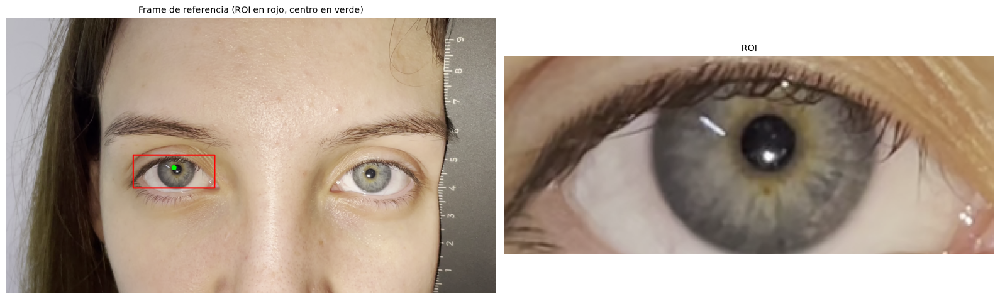

In [3]:
ctx = preparar_referencia(cfg)
roi_rgb, roi_gray = ctx["roi_rgb"], ctx["roi_gray"]
cx, cy = ctx["centro_roi"]                 # centro de la pupila dentro de la ROI
info = ctx["info"]
fps = info["fps"]
print(f"{info['ancho']}x{info['alto']} | {fps:.2f} fps | {info['n_frames']} frames | {info['duracion_s']:.1f} s")
print("Frame de referencia:", ctx["frame_index"], "| centro en el frame:", ctx["centro_frame"],
      "(automático)" if ctx["centro_automatico"] else "(config)")

vis = ctx["frame_rgb"].copy()
x0, y0, w, h = ctx["roi_rect"]
cv2.rectangle(vis, (x0, y0), (x0 + w, y0 + h), (255, 0, 0), 4)
cv2.circle(vis, tuple(map(int, ctx["centro_frame"])), 10, (0, 255, 0), -1)
mostrar([vis, roi_rgb], ["Frame de referencia (ROI en rojo, centro en verde)", "ROI"], figsize=(16, 5))

In [83]:
# OPCIONAL — elegir el centro a mano con una ventana de OpenCV (requiere entorno gráfico):
# from pupila.video import seleccionar_centro_cv2
# c = seleccionar_centro_cv2(cv2.cvtColor(roi_rgb, cv2.COLOR_RGB2BGR))   # (x, y) dentro de la ROI
# cfg["centro_pupila_inicial"] = [x0 + c[0], y0 + c[1]]                  # a coordenadas del frame
# ctx = preparar_referencia(cfg); roi_rgb, roi_gray = ctx["roi_rgb"], ctx["roi_gray"]; cx, cy = ctx["centro_roi"]

# Módulo 1 — Procesamiento y análisis de imagen

### 1.1 Representación, cuantización, espacios de color

{'ancho': 320, 'alto': 130, 'canales': 3, 'bits_por_canal': 8}


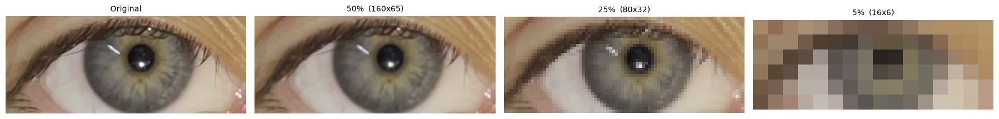

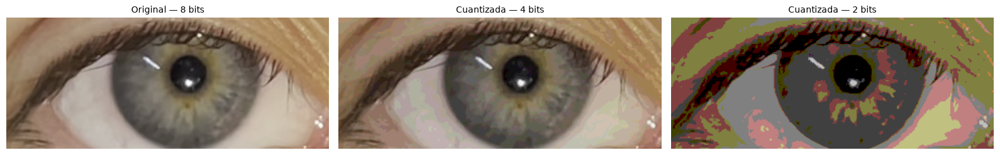

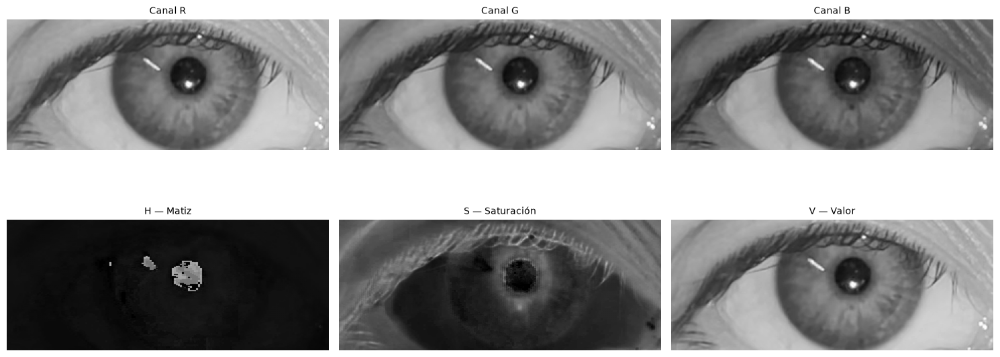

H: 0 → 178 | S: 0 → 185 | V: 16 → 255


In [8]:
print(m1.info_imagen(roi_rgb))
sub = m1.submuestrear(roi_rgb, (0.50, 0.25, 0.05))
mostrar([roi_rgb, *sub.values()],
        ["Original"] + [f"{int(f * 100)}%  ({v.shape[1]}x{v.shape[0]})" for f, v in sub.items()], figsize=(18, 4))

mostrar([roi_rgb, m1.cuantizar_bits(roi_rgb, 4), m1.cuantizar_bits(roi_rgb, 2)],
        ["Original — 8 bits", "Cuantizada — 4 bits", "Cuantizada — 2 bits"], figsize=(16, 4))

R, G, B = m1.separar_canales_rgb(roi_rgb)
H, S, V = m1.convertir_hsv(roi_rgb)
mostrar([R, G, B, H, S, V], ["Canal R", "Canal G", "Canal B", "H — Matiz", "S — Saturación", "V — Valor"],
        filas=2, figsize=(15, 7))
print(f"H: {H.min()} → {H.max()} | S: {S.min()} → {S.max()} | V: {V.min()} → {V.max()}")

### 1.2 Escala de grises, histograma, brillo y contraste

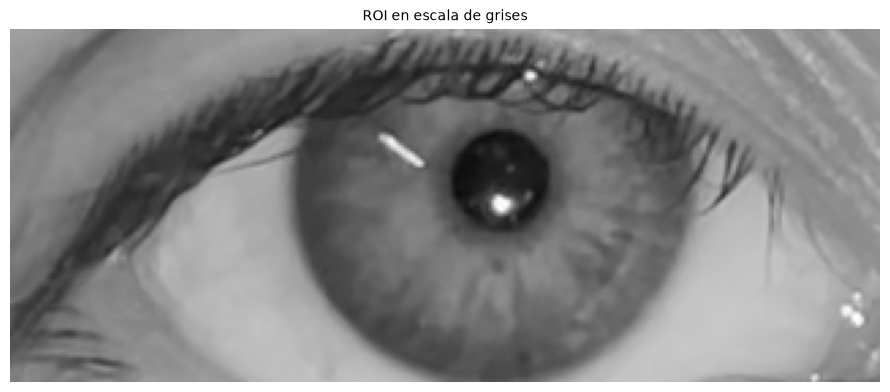

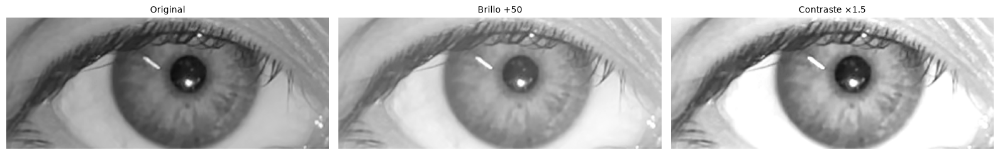

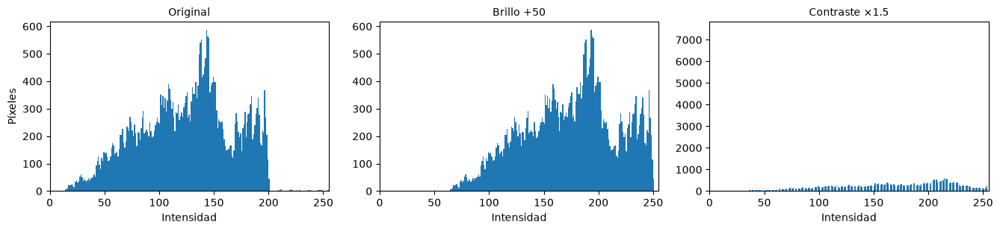

In [9]:
mostrar([roi_gray], ["ROI en escala de grises"], figsize=(9, 4))
brillo, contraste = m1.modificar_brillo_contraste(roi_gray, brillo=50, contraste=1.5)
mostrar([roi_gray, brillo, contraste], ["Original", "Brillo +50", "Contraste ×1.5"], figsize=(16, 4))
histogramas([roi_gray, brillo, contraste], ["Original", "Brillo +50", "Contraste ×1.5"])

*Análisis (versión original):* al sumar una constante, el histograma se desplaza completo. Al multiplicar por 1.5 los extremos
se corren hacia los extremos del rango y se usa mejor el intervalo 0–255 (efecto parecido a una ecualización).

### 1.3 Transformación lineal y ecualización

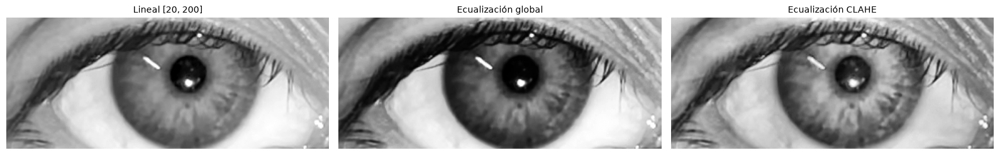

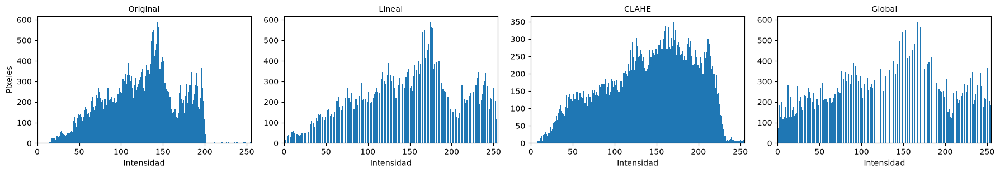

In [10]:
lineal = m1.transformacion_lineal(roi_gray, f1=20, f2=200)
eq = m1.ecualizar(roi_gray)
mostrar([lineal, eq["global"], eq["clahe"]], ["Lineal [20, 200]", "Ecualización global", "Ecualización CLAHE"], figsize=(16, 4))
histogramas([roi_gray, lineal, eq["clahe"], eq["global"]], ["Original", "Lineal", "CLAHE", "Global"])

*Análisis (versión original):* la global y CLAHE pierden nitidez frente a la lineal y oscurecen las pestañas hasta confundirlas con la pupila;
la transformación lineal es la que mejor distingue pupila e iris, y CLAHE da los peores resultados.

### 1.4 Ruido y filtrado espacial

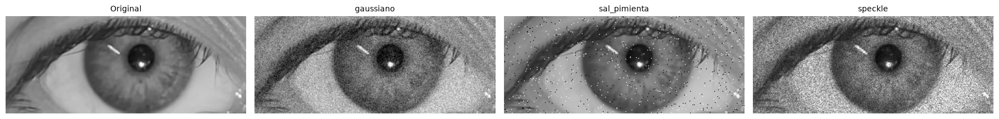

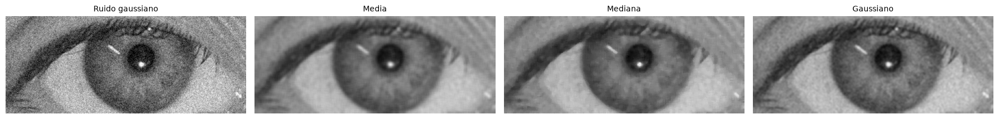

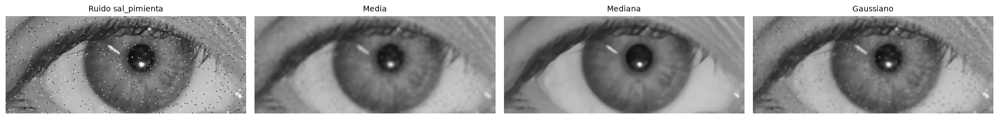

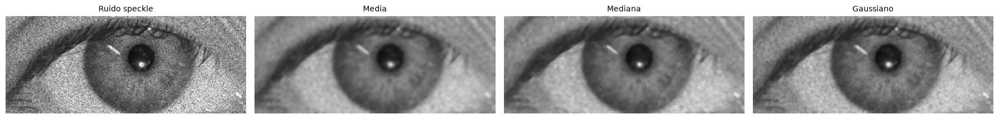

PSNR (dB)   SSIM
gaussiano    media         30.651  0.845
             mediana       30.303  0.808
             gaussiano     31.561  0.828
sal_pimienta media         30.607  0.854
             mediana       33.564  0.942
             gaussiano     31.615  0.855
speckle      media         29.813  0.799
             mediana       29.032  0.752
             gaussiano     29.850  0.761

In [11]:
ruido = m1.agregar_ruido(roi_gray, sigma_gauss=20, prob_sp=0.02, sigma_speckle=0.2, seed=0)
mostrar([roi_gray, *ruido.values()], ["Original", *ruido.keys()], figsize=(18, 4))

filtrados = {n: m1.filtrar_espacial(img, k=5) for n, img in ruido.items()}
for n, img in ruido.items():
    mostrar([img, *filtrados[n].values()], [f"Ruido {n}", "Media", "Mediana", "Gaussiano"], figsize=(18, 4))

tabla = pd.DataFrame({(n, f): m1.metricas_calidad(roi_gray, im)
                      for n, d in filtrados.items() for f, im in d.items()}).T
display(tabla.round(3))

*Análisis:* para ruido gaussiano los tres filtros lo reducen de forma similar; para sal y pimienta el mejor es la **mediana**;
para speckle, media y mediana dan resultados parecidos (más suavizado, menos nitidez) y el gaussiano conserva nitidez pero queda moteado.

### 1.5 Detección de bordes (Roberts, Sobel, Prewitt, Laplaciano, Canny)

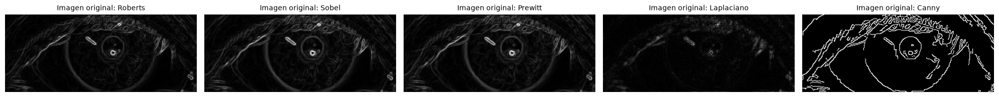

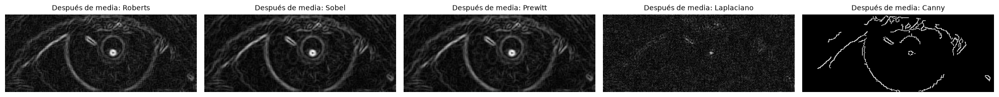

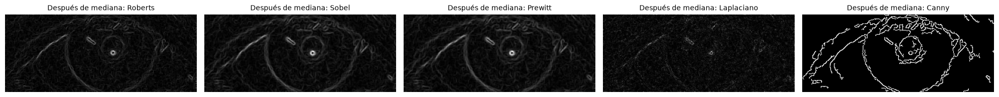

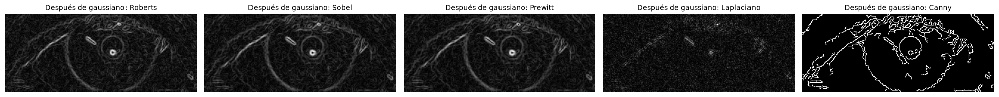

Continuidad del contorno pupilar (fracción del contorno cubierta por borde, 0–1):


,Roberts,Sobel,Prewitt,Laplaciano,Canny
Imagen original,0.651,0.648,0.642,0.622,0.721
Después de media,0.603,0.572,0.552,0.817,0.384
Después de mediana,0.683,0.598,0.585,0.725,0.688
Después de gaussiano,0.642,0.662,0.635,0.659,0.707


In [12]:
mask_ref, _ = m2.segmentar_pupila(roi_gray, cx, cy)       # máscara de referencia para medir continuidad
base_gauss = ruido["gaussiano"]
imagenes_bordes = {"Imagen original": roi_gray,
                   "Después de media": filtrados["gaussiano"]["media"],
                   "Después de mediana": filtrados["gaussiano"]["mediana"],
                   "Después de gaussiano": filtrados["gaussiano"]["gaussiano"]}
for nombre, img in imagenes_bordes.items():
    b = m1.detectar_bordes(img)
    mostrar(list(b.values()), [f"{nombre}: {k}" for k in b], figsize=(20, 3.5), vmin=None, vmax=None)

cont = pd.DataFrame({nom: {op: m1.continuidad_contorno_pupilar(b, mask_ref) for op, b in m1.detectar_bordes(img).items()}
                     for nom, img in imagenes_bordes.items()}).T
print("Continuidad del contorno pupilar (fracción del contorno cubierta por borde, 0–1):")
display(cont.round(3))

*Análisis (versión original):* Canny es el detector que mantiene el borde pupilar más continuo, aunque no logra un borde totalmente continuo;
aplicado sobre la imagen original da el mejor contorno de pupila e iris.

### 1.6 Transformada de Fourier 2D: magnitud, fase y reconstrucciones

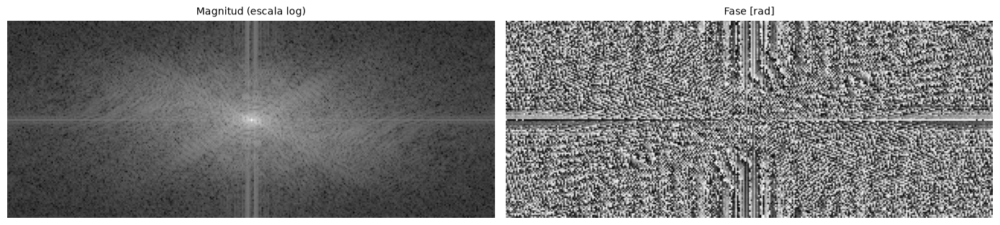

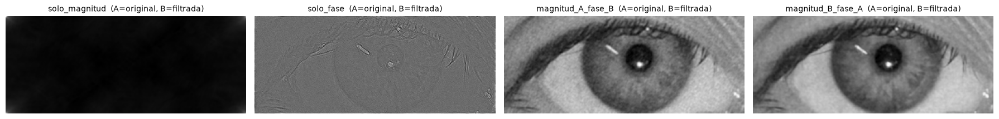

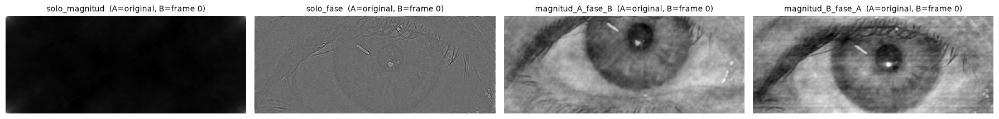

SSIM de cada reconstrucción (normalizada) contra la ROI original:


,SSIM
solo_magnitud,0.073
solo_fase,0.494
magnitud_A_fase_B,0.824
magnitud_B_fase_A,0.908
magnitud_A_fase_B (frame 0),0.250
magnitud_B_fase_A (frame 0),0.673


In [13]:
A = m1.fft2d(roi_gray)
mostrar([A["magnitud_log"], A["fase"]], ["Magnitud (escala log)", "Fase [rad]"], figsize=(14, 4), vmin=None, vmax=None)

img_filtrada = filtrados["gaussiano"]["gaussiano"]           # ruido gaussiano + filtro gaussiano
otro_frame = cv2.cvtColor(recortar_roi(leer_frame(cfg["video_path"], 0), ctx["centro_frame"],
                                       cfg["roi"]["ancho"], cfg["roi"]["alto"],
                                       cfg["roi"]["centro_pupila_en_roi"])[0], cv2.COLOR_BGR2GRAY)

rec_f = m1.reconstrucciones_fourier(roi_gray, img_filtrada)   # original vs filtrada
rec_o = m1.reconstrucciones_fourier(roi_gray, otro_frame)     # original vs otro instante del video
mostrar(list(rec_f.values()), [f"{k}  (A=original, B=filtrada)" for k in rec_f], figsize=(18, 4), vmin=None, vmax=None)
mostrar(list(rec_o.values()), [f"{k}  (A=original, B=frame 0)" for k in rec_o], figsize=(18, 4), vmin=None, vmax=None)

def a_gris(x):
    x = x - x.min()
    return (255 * x / max(x.max(), 1e-9)).astype(np.uint8)
print("SSIM de cada reconstrucción (normalizada) contra la ROI original:")
display(pd.Series({k: m1.metricas_calidad(roi_gray, a_gris(v))["SSIM"] for k, v in {**rec_f, **{k + ' (frame 0)': v for k, v in rec_o.items() if 'B' in k}}.items()}).round(3).to_frame("SSIM"))

*Discusión a completar:* ¿qué reconstrucción conserva la información estructural? (comparar `solo_fase` vs `solo_magnitud` y las cruzadas: la que lleva la **fase** de la imagen original debería conservar bordes y estructura.)

### 1.7 Densidad espectral de potencia (PSD)

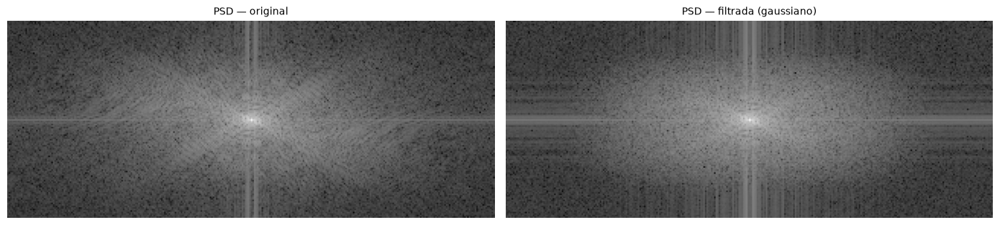

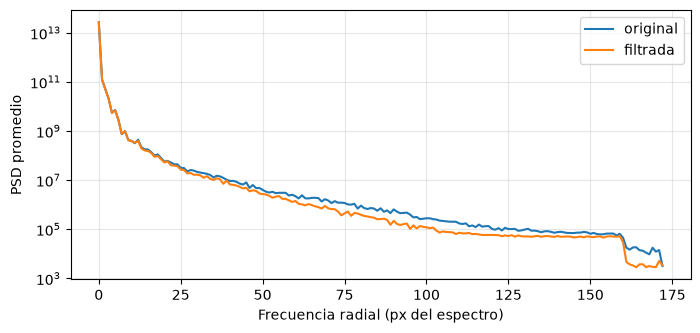

Energía en baja frecuencia (radio ≤ 20): original 0.9954 | filtrada 0.9965
Energía en baja frecuencia (radio ≤ 40): original 0.9985 | filtrada 0.9991
Energía en baja frecuencia (radio ≤ 80): original 0.9998 | filtrada 0.9999


In [14]:
P0, P0log = m1.psd(roi_gray)
P1, P1log = m1.psd(img_filtrada)
mostrar([P0log, P1log], ["PSD — original", "PSD — filtrada (gaussiano)"], figsize=(14, 4), vmin=None, vmax=None)

plt.figure(figsize=(8, 3.5))
plt.semilogy(m1.psd_radial(P0), label="original")
plt.semilogy(m1.psd_radial(P1), label="filtrada")
plt.xlabel("Frecuencia radial (px del espectro)"); plt.ylabel("PSD promedio"); plt.legend(); plt.grid(alpha=0.3)
plt.show()
for r in (20, 40, 80):
    print(f"Energía en baja frecuencia (radio ≤ {r}): original {m1.fraccion_energia_baja_frecuencia(P0, r):.4f} | "
          f"filtrada {m1.fraccion_energia_baja_frecuencia(P1, r):.4f}")

*Análisis (versión original):* en la PSD filtrada la energía queda más concentrada en bajas frecuencias: el filtro gaussiano atenúa las altas frecuencias,
pero los bordes viven justamente en esas componentes, así que se pierde información de borde.

### 1.8 Filtrado en frecuencia y comparación con el filtrado espacial

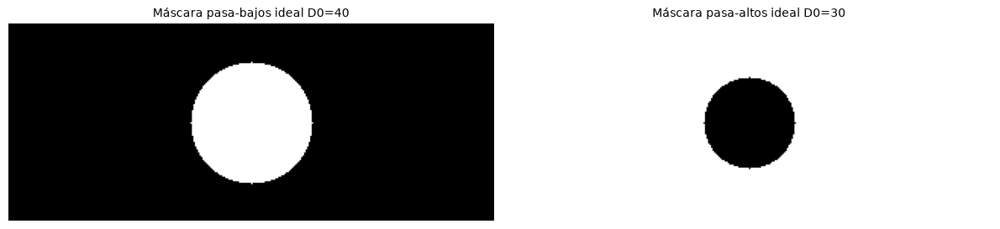

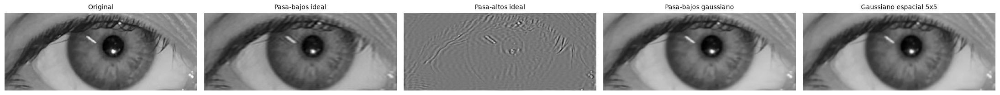

In [15]:
bajos, Hb = m1.filtro_frecuencia(roi_gray, 40, "pasa_bajos", "ideal")
altos, Ha = m1.filtro_frecuencia(roi_gray, 30, "pasa_altos", "ideal")
bajos_g, _ = m1.filtro_frecuencia(roi_gray, 40, "pasa_bajos", "gaussiano")
altos_g, _ = m1.filtro_frecuencia(roi_gray, 30, "pasa_altos", "gaussiano")
gauss_esp = cv2.GaussianBlur(roi_gray, (5, 5), 0)

mostrar([Hb, Ha], ["Máscara pasa-bajos ideal D0=40", "Máscara pasa-altos ideal D0=30"], figsize=(12, 4), vmin=0, vmax=1)
mostrar([roi_gray, bajos, altos, bajos_g, gauss_esp],
        ["Original", "Pasa-bajos ideal", "Pasa-altos ideal", "Pasa-bajos gaussiano", "Gaussiano espacial 5x5"],
        figsize=(22, 4), vmin=None, vmax=None)

### 1.9 Pregunta: ¿qué filtro preserva el borde pupilar y elimina los destellos? — PSNR / SSIM

In [16]:
UMBRAL_DESTELLO = 205
ap = cv2.morphologyEx(roi_gray, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (25, 25)))
candidatos = {
    "Sin filtrar": roi_gray,
    "Media 5x5": cv2.blur(roi_gray, (5, 5)),
    "Mediana 5x5": cv2.medianBlur(roi_gray, 5),
    "Mediana 9x9": cv2.medianBlur(roi_gray, 9),
    "Gaussiano 5x5": gauss_esp,
    "Pasa-bajos ideal D0=40": bajos,
    "Pasa-bajos gaussiano D0=40": bajos_g,
    "Apertura morfológica 25x25 (grises)": ap,
}
zona = cv2.dilate(mask_ref, np.ones((15, 15), np.uint8)) > 0      # pupila + entorno inmediato
filas = {}
for nombre, img in candidatos.items():
    u8 = m1.a_uint8(img)
    filas[nombre] = {**m1.metricas_calidad(roi_gray, u8),
                     "Continuidad borde (Canny)": m1.continuidad_contorno_pupilar(cv2.Canny(u8, 50, 150), mask_ref),
                     "Píxeles de destello remanentes": int(((u8 > UMBRAL_DESTELLO) & zona).sum())}
display(pd.DataFrame(filas).T.round(3))

/Users/somi/Documents/PSIB/Guia_Imagenes_Biomed/PSIB_Guia_Imag_Biomed_Grupo15/.venv/lib/python3.14/site-packages/skimage/metrics/simple_metrics.py:171: RuntimeWarning: divide by zero encountered in scalar divide
  return 10 * np.log10((data_range**2) / err)


,PSNR (dB),SSIM,Continuidad borde (Canny),Píxeles de destello remanentes
Sin filtrar,inf,1.000,0.721,61.0
Media 5x5,32.176,0.918,0.450,10.0
Mediana 5x5,33.641,0.943,0.707,20.0
Mediana 9x9,28.876,0.841,0.474,0.0
Gaussiano 5x5,36.238,0.969,0.675,22.0
Pasa-bajos ideal D0=40,33.885,0.937,0.672,42.0
Pasa-bajos gaussiano D0=40,36.475,0.972,0.686,32.0
Apertura morfológica 25x25 (grises),21.184,0.740,0.231,0.0


*Cómo leer la tabla:* PSNR/SSIM miden cuánto se parece cada resultado a la original (ojo: **el destello también es parte de la original**, así que eliminarlo baja PSNR/SSIM).
Por eso se mira junto con la *continuidad del borde* y los *píxeles de destello remanentes*: el filtro buscado es el que mantiene alta la continuidad y deja ≈0 destellos.
Completá acá tu conclusión con los números obtenidos.

# Módulo 2 — Segmentación y morfología matemática

### 2.1 Otsu y K-Means

Umbral de Otsu: 121.0


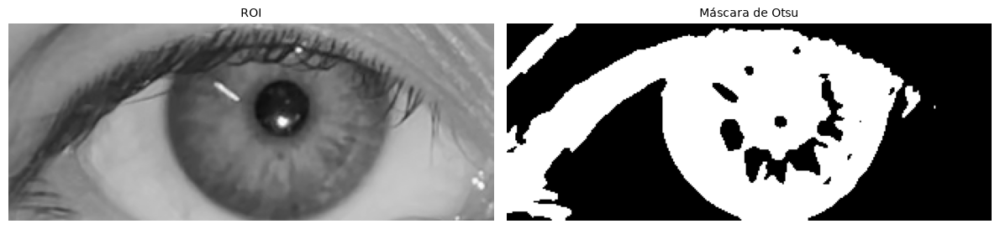

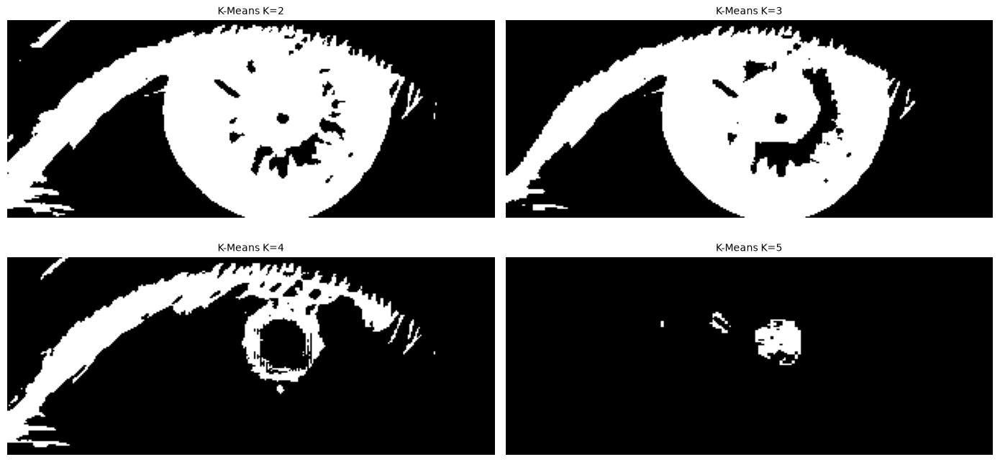

In [17]:
umbral, mask_otsu = m2.segmentar_otsu(roi_gray)
print("Umbral de Otsu:", umbral)
mostrar([roi_gray, mask_otsu], ["ROI", "Máscara de Otsu"], figsize=(12, 4))

km = m2.segmentar_kmeans(roi_rgb, ks=range(2, 6))
mostrar(list(km.values()), [f"K-Means K={k}" for k in km], filas=2, figsize=(14, 7))

### 2.2 Contornos activos (Snakes)

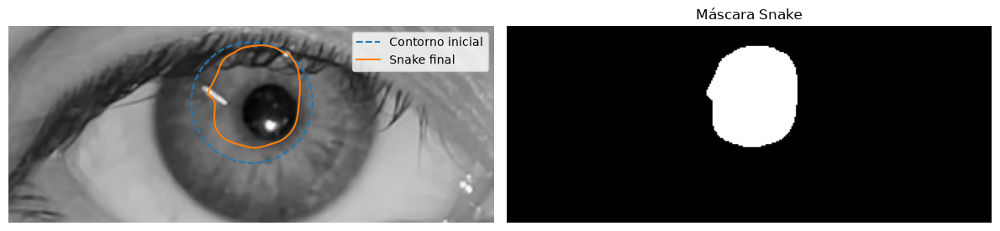

In [4]:
init, snake, mask_snake = m2.segmentar_snake(roi_gray, (cx, cy), radio=40)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].imshow(roi_gray, cmap="gray"); axs[0].plot(init[:, 1], init[:, 0], "--", label="Contorno inicial")
axs[0].plot(snake[:, 1], snake[:, 0], label="Snake final"); axs[0].legend(); axs[0].axis("off")
axs[1].imshow(mask_snake, cmap="gray"); axs[1].set_title("Máscara Snake"); axs[1].axis("off")
plt.tight_layout(); plt.show()

### 2.3 Watershed

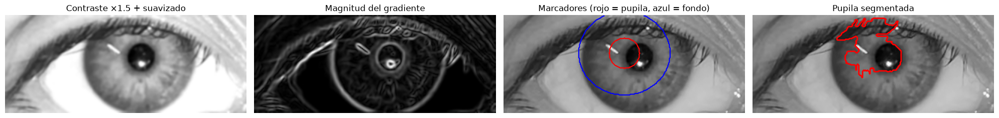

In [19]:
suave = m2.preparar_para_watershed(roi_gray, contraste=1.5)
grad = m2.gradiente_sobel(suave, ksize=7)
marc = m2.marcadores_pupila(roi_gray.shape, cx, cy, radio=20)
mask_ws, cont_ws = m2.segmentar_pupila(roi_gray, cx, cy, radio=20, cerrar=False)

fig, axs = plt.subplots(1, 4, figsize=(20, 4))
axs[0].imshow(suave, cmap="gray"); axs[0].set_title("Contraste ×1.5 + suavizado")
axs[1].imshow(grad, cmap="gray"); axs[1].set_title("Magnitud del gradiente")
axs[2].imshow(roi_gray, cmap="gray"); axs[2].contour(marc == 1, colors="r"); axs[2].contour(marc == 2, colors="b")
axs[2].set_title("Marcadores (rojo = pupila, azul = fondo)")
axs[3].imshow(roi_gray, cmap="gray"); axs[3].contour(mask_ws > 0, colors="r", linewidths=2); axs[3].set_title("Pupila segmentada")
for a in axs: a.axis("off")
plt.tight_layout(); plt.show()

*Análisis (versión original):* Watershed da un contorno bastante cercano a la pupila, aunque irregular.

### 2.4 Morfología matemática, esqueleto y comparación de combinaciones

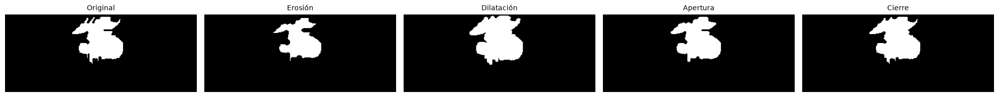

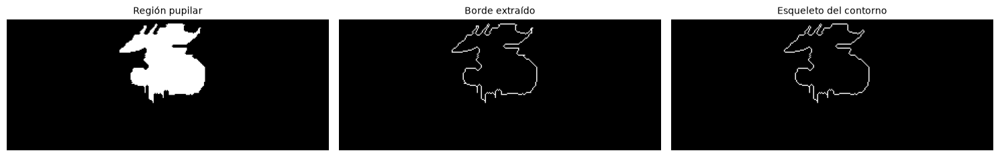

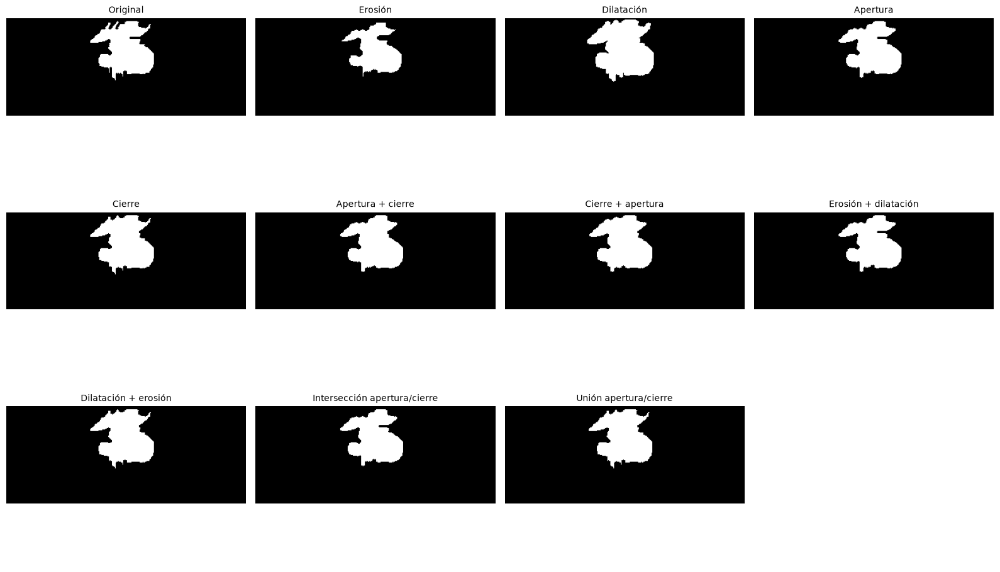

In [20]:
ops = m2.operaciones_morfologicas(mask_ws, tam=5)
mostrar(list(ops.values()), list(ops.keys()), figsize=(20, 3.5), vmin=0, vmax=255)

borde, esqueleto = m2.esqueletizar_contorno(mask_ws)
mostrar([mask_ws, borde, esqueleto.astype(np.uint8) * 255], ["Región pupilar", "Borde extraído", "Esqueleto del contorno"], figsize=(15, 4))

comb = m2.combinaciones_morfologicas(mask_ws, tam=5)
mostrar([(np.asarray(m) > 0).astype(float) for m in comb.values()], list(comb.keys()), filas=3, figsize=(16, 10), vmin=0, vmax=1)

In [21]:
# Referencia: contorno marcado a mano (≥5 puntos (x, y) sobre el borde pupilar, en coordenadas de la ROI).
# Si se deja en None, las métricas se calculan contra la propia máscara de Watershed (solo mide cuánto cambia cada operación).
PUNTOS_MANUALES = None          # ej.: [(120, 40), (150, 22), (185, 35), (190, 62), (140, 75)]
referencia = m2.mascara_desde_puntos(PUNTOS_MANUALES, roi_gray.shape) if PUNTOS_MANUALES else mask_ws
nombre_ref = "manual" if PUNTOS_MANUALES else "Watershed"

print(f"Segmentadores vs. referencia ({nombre_ref}):")
segmentadores = {"Otsu": mask_otsu, **{f"K-Means K={k}": m for k, m in km.items()}, "Snake": mask_snake, "Watershed": mask_ws}
display(m2.tabla_metricas(segmentadores, referencia).round(4))

print(f"Operaciones morfológicas vs. referencia ({nombre_ref}):")
display(m2.tabla_metricas(comb, referencia).round(4))

Segmentadores vs. referencia (Watershed):


,Área (px),Cambio de área (%),Dice,IoU (Jaccard),Píxeles modificados (%)
Otsu,18881.0,383.0136,0.3136,0.1859,37.6058
K-Means K=2,18255.0,366.9992,0.3374,0.2029,35.3029
K-Means K=3,16340.0,318.0097,0.3558,0.2164,31.3582
K-Means K=4,6738.0,72.3715,0.2989,0.1757,17.9447
K-Means K=5,633.0,-83.8066,0.2651,0.1528,8.0240
Snake,1728.0,-55.7943,0.6007,0.4293,5.4111
Watershed,3909.0,0.0000,1.0000,1.0000,0.0000


Operaciones morfológicas vs. referencia (Watershed):


,Área (px),Cambio de área (%),Dice,IoU (Jaccard),Píxeles modificados (%)
Original,3909.0,0.0000,1.0000,1.0000,0.0000
Erosión,3063.0,-21.6424,0.8787,0.7836,2.0337
Dilatación,4818.0,23.2540,0.8958,0.8113,2.1851
Apertura,3779.0,-3.3257,0.9831,0.9667,0.3125
Cierre,4052.0,3.6582,0.9820,0.9647,0.3438
Apertura + cierre,3832.0,-1.9698,0.9764,0.9538,0.4399
Cierre + apertura,3987.0,1.9954,0.9737,0.9487,0.5000
Erosión + dilatación,3779.0,-3.3257,0.9831,0.9667,0.3125
Dilatación + erosión,4052.0,3.6582,0.9820,0.9647,0.3438
Intersección apertura/cierre,3779.0,-3.3257,0.9831,0.9667,0.3125


*Análisis (versión original):* la erosión es la que más área quita y la dilatación la que más agrega; la apertura modifica muy poco y el cierre no produjo cambios con el elemento estructurante usado.
Las combinaciones no mejoran de forma apreciable la máscara; el cierre (dilatación→erosión) o la unión cierre/apertura son las más adecuadas porque conservan la morfología.
Si usás referencia manual, Dice/IoU pasan a medir *precisión real* y no solo cuánto cambió la máscara.

# Módulo 3 — Descriptores, textura y dinámica temporal

### 3.1 Descriptores morfométricos (frame de referencia)

,Pupila (frame de referencia)
Área (px²),3878.5000
Perímetro (px),395.9483
Centroide X_c (px),158.5804
Centroide Y_c (px),41.3323
Circularidad,0.3109
Excentricidad,0.3558
Eje mayor (px),78.6569
Eje menor (px),73.5098


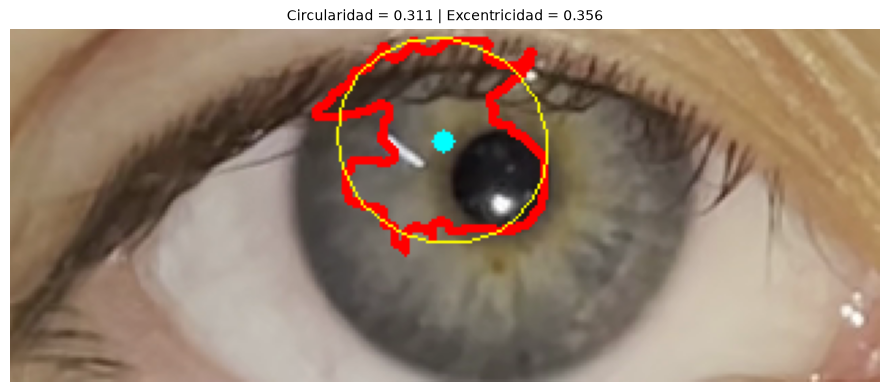

In [22]:
roi_cuant, gray_cuant = m3.cuantizar_roi(roi_rgb, roi_gray, niveles=32)
mask_pupila, contorno = m2.segmentar_pupila(roi_gray, cx, cy)       # Watershed + cierre 5x5
desc, elipse = m3.descriptores_morfometricos(contorno)
display(pd.DataFrame(desc, index=["Pupila (frame de referencia)"]).T.round(4))

vis = roi_rgb.copy()
cv2.drawContours(vis, [contorno], -1, (255, 0, 0), 2)
cv2.ellipse(vis, elipse, (255, 255, 0), 1)
cv2.circle(vis, (int(round(desc["Centroide X_c (px)"])), int(round(desc["Centroide Y_c (px)"]))), 4, (0, 255, 255), -1)
mostrar([vis], [f"Circularidad = {desc['Circularidad']:.3f} | Excentricidad = {desc['Excentricidad']:.3f}"], figsize=(9, 4))

### 3.2 Textura de primer orden y GLCM (pupila e iris)

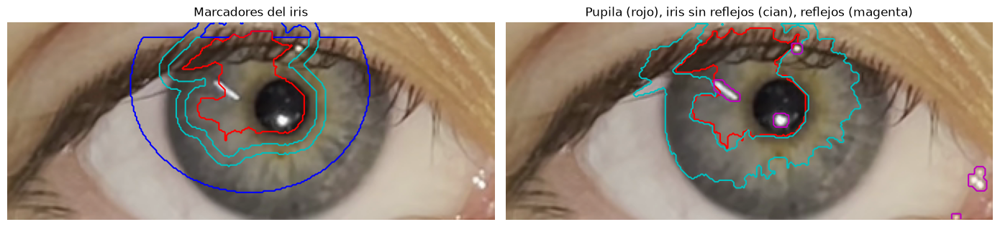

Píxeles pupila: 4052 | iris: 6234 | iris sin reflejos: 6197
PRIMER ORDEN — PUPILA


,Media,Desvío,Entropía (bits),Asimetría
R,9.962,4.924,4.064,0.628
G,8.833,4.899,3.985,0.934
B,7.671,4.650,3.843,1.549


PRIMER ORDEN — IRIS


,Media,Desvío,Entropía (bits),Asimetría
R,12.857,3.476,3.759,0.215
G,11.527,3.410,3.757,0.028
B,9.701,3.072,3.575,0.184


GLCM — PUPILA


,Contraste,Homogeneidad,Energía,Correlación
R,2.7910,0.6814,0.1570,0.9431
G,2.7816,0.6874,0.1642,0.9426
B,2.7597,0.6907,0.1710,0.9366


GLCM — IRIS


,Contraste,Homogeneidad,Energía,Correlación
R,1.0627,0.7541,0.1833,0.9551
G,1.0308,0.7602,0.1887,0.9549
B,1.0366,0.7622,0.2072,0.9435


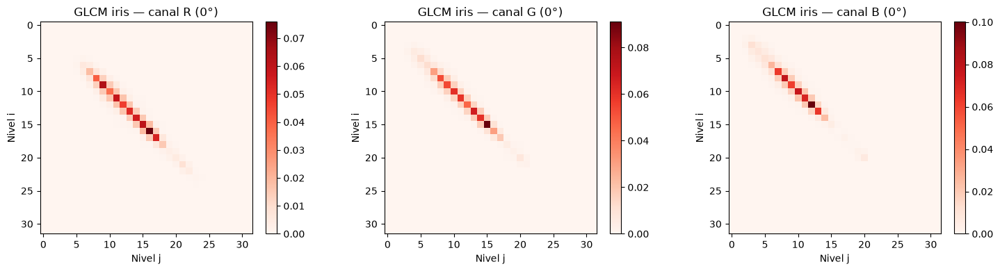

In [23]:
mask_iris, marc_iris = m3.segmentar_iris(roi_gray, mask_pupila, (desc["Centroide X_c (px)"], desc["Centroide Y_c (px)"]))
mask_iris_ok, mask_brillo = m3.mascara_sin_reflejos(roi_gray, mask_iris, umbral_brillo=205)

fig, axs = plt.subplots(1, 2, figsize=(14, 4))
axs[0].imshow(roi_rgb); axs[0].contour(marc_iris == 1, colors="c"); axs[0].contour(marc_iris == 2, colors="b"); axs[0].contour(marc_iris == 3, colors="r")
axs[0].set_title("Marcadores del iris")
axs[1].imshow(roi_rgb); axs[1].contour(mask_pupila > 0, colors="r"); axs[1].contour(mask_iris_ok > 0, colors="c"); axs[1].contour(mask_brillo > 0, colors="m")
axs[1].set_title("Pupila (rojo), iris sin reflejos (cian), reflejos (magenta)")
for a in axs: a.axis("off")
plt.tight_layout(); plt.show()
print("Píxeles pupila:", cv2.countNonZero(mask_pupila), "| iris:", cv2.countNonZero(mask_iris), "| iris sin reflejos:", cv2.countNonZero(mask_iris_ok))

print("PRIMER ORDEN — PUPILA"); display(m3.estadisticas_primer_orden(roi_cuant, mask_pupila).round(3))
print("PRIMER ORDEN — IRIS");   display(m3.estadisticas_primer_orden(roi_cuant, mask_iris_ok).round(3))

glcm_pup, glcm_iris, glcms = m3.textura_glcm_por_canal(roi_cuant, mask_pupila, mask_iris_ok)
print("GLCM — PUPILA"); display(glcm_pup.round(4))
print("GLCM — IRIS");   display(glcm_iris.round(4))

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, canal in zip(axs, "RGB"):
    im = ax.imshow(glcms[("Iris", canal)][:, :, 0, 0], cmap="Reds")
    ax.set_title(f"GLCM iris — canal {canal} (0°)"); ax.set_xlabel("Nivel j"); ax.set_ylabel("Nivel i")
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

*Análisis (versión original, validar con tus números):* la pupila es más oscura y uniforme que el iris (medias, desvío y entropía menores); su asimetría es positiva y alta por el reflejo del flash no excluido.
Entre canales las diferencias son pequeñas; R muestra mayor contraste y menor homogeneidad, por lo que se lo considera el más informativo para el estroma iridiano.

### 3.3 Procesamiento del video completo

`procesar_video` hace **una sola pasada**: sigue la pupila frame a frame, recorta la ROI, quita reflejos, segmenta con Watershed
(probando tres radios de marcador), calcula área/diámetro/circularidad y **interpola** los frames inválidos
(circularidad < `umbral_circularidad` o sin segmentación: parpadeos, errores puntuales).

In [24]:
df = m3.procesar_video(cfg["video_path"], ctx["centro_frame"], cfg)
display(df.head())
print(m3.resumen_artefactos(df, fps))

  frame 615/615


,frame,tiempo_s,area_cruda_px2,diametro_crudo_px,circularidad,centro_x_px,centro_y_px,brillo_medio,valido,area_px2,diametro_px,interpolado
0,0,0.000000,580.5,27.186680,0.891246,671,557,153.510465,True,580.5,27.186680,False
1,1,0.033358,1070.0,36.910247,0.929695,670,560,153.368875,True,1070.0,36.910247,False
2,2,0.066715,575.5,27.069344,0.884434,668,559,153.161265,False,1039.0,36.367587,True
3,3,0.100073,1008.0,35.824928,0.925668,668,561,153.266734,True,1008.0,35.824928,False
4,4,0.133431,1181.0,38.777518,0.945449,667,558,153.075183,True,1181.0,38.777518,False


{'frames_interpolados': 19, 'frames_interpolados_pct': 3.089430894308943, 'racha_mas_larga_frames': 4, 'racha_mas_larga_s': 0.1334308943089431}


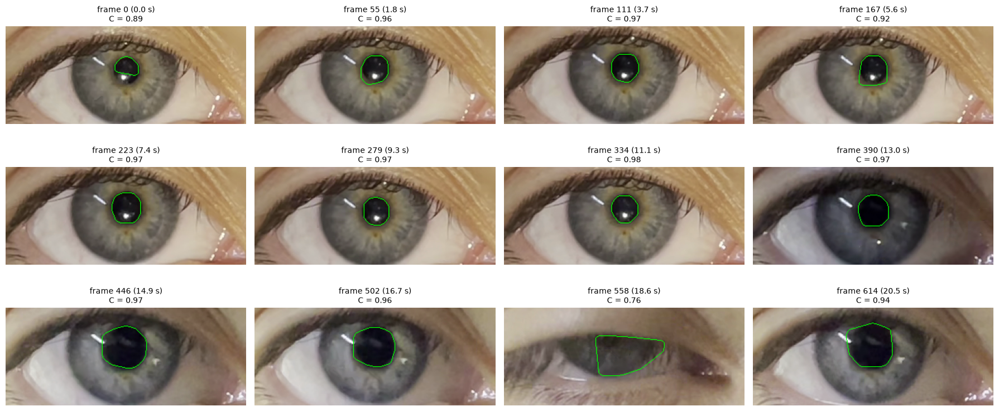

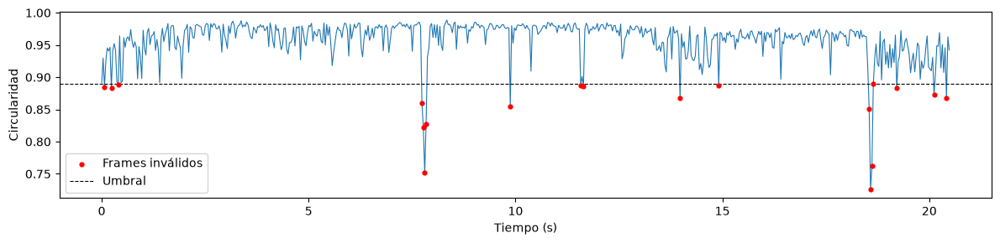

In [25]:
# Verificación visual en 12 frames repartidos a lo largo del video
indices = np.linspace(0, len(df) - 1, 12).astype(int)
fig, axs = plt.subplots(3, 4, figsize=(18, 8))
for ax, i in zip(axs.ravel(), indices):
    frame = leer_frame(cfg["video_path"], i)
    roi_i, (cxi, cyi) = recortar_roi(frame, (int(df.loc[i, "centro_x_px"]), int(df.loc[i, "centro_y_px"])),
                                     cfg["roi"]["ancho"], cfg["roi"]["alto"], cfg["roi"]["centro_pupila_en_roi"])
    c = m3.medir_pupila(cv2.cvtColor(roi_i, cv2.COLOR_BGR2GRAY), cxi, cyi)
    v = cv2.cvtColor(roi_i, cv2.COLOR_BGR2RGB)
    if c is not None:
        cv2.drawContours(v, [c], -1, (0, 255, 0), 1)
    ax.imshow(v); ax.axis("off")
    ax.set_title(f"frame {i} ({i / fps:.1f} s)" + (f"\nC = {m3.circularidad(c):.2f}" if c is not None else "\nsin segmentación"), fontsize=10)
plt.tight_layout(); plt.show()

plt.figure(figsize=(12, 3))
plt.plot(df["tiempo_s"], df["circularidad"], lw=0.8)
plt.scatter(df.loc[~df["valido"], "tiempo_s"], df.loc[~df["valido"], "circularidad"], c="r", s=12, zorder=3, label="Frames inválidos")
plt.axhline(cfg["video"]["umbral_circularidad"], color="k", ls="--", lw=0.8, label="Umbral")
plt.xlabel("Tiempo (s)"); plt.ylabel("Circularidad"); plt.legend(); plt.tight_layout(); plt.show()

### 3.4 Validación contra medición manual (MAE / RMSE)

In [27]:
ANOT = cfg["anotaciones_manuales"] or str(Path("data/reference/anotaciones_manuales.csv").resolve())
if Path(ANOT).exists():
    tabla_val, comp = m3.validar_contra_manual(df, ANOT)
    display(tabla_val.round(2))
    fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
    for ax, (a, m, n) in zip(axs, [("area_px2", "area_manual_px2", "Área (px²)"), ("diametro_px", "diametro_manual_px", "Diámetro (px)")]):
        ax.scatter(comp[m], comp[a], c=np.where(comp["interpolado"], "tab:red", "tab:blue"), s=20)
        lim = [min(comp[m].min(), comp[a].min()), max(comp[m].max(), comp[a].max())]
        ax.plot(lim, lim, "k--", lw=0.8); ax.set_xlabel(f"{n} manual"); ax.set_ylabel(f"{n} automático"); ax.set_title(n)
    plt.tight_layout(); plt.show()
else:
    print("No hay anotaciones manuales en", ANOT)

# Para anotar 25 frames a mano (ventana OpenCV; Enter acepta, u deshace, s saltea):
# frames_manual = np.linspace(0, len(df) - 1, 25).astype(int)
# m3.anotar_frames_manualmente(cfg["video_path"], frames_manual, df[["centro_x_px", "centro_y_px"]].values, cfg, ANOT)

No hay anotaciones manuales en /Users/somi/Documents/PSIB/Guia_Imagenes_Biomed/PSIB_Guia_Imag_Biomed_Grupo15/proyecto_ojo/data/reference/anotaciones_manuales.csv


*Análisis (versión original, validar):* la segmentación automática concuerda con la manual (error medio ≈2.6 % en diámetro y ≈5.3 % en área); el punto que se aleja de la diagonal es un frame interpolado.

### 3.5 Curva temporal y parámetros fisiológicos

,parametro,valor,unidad
0,t_estimulo_s,12.375715,s
1,frame_estimulo,371.000000,frame
2,t_inicio_constriccion_s,NaN,s
3,latencia_ms,NaN,ms
4,diametro_basal_px,35.918087,px
5,diametro_minimo_px,36.528825,px
6,amplitud_diametro_px,-0.610737,px
7,area_basal_px2,1013.250000,px2
8,area_minima_px2,1048.000000,px2
9,amplitud_area_px2,-34.750000,px2


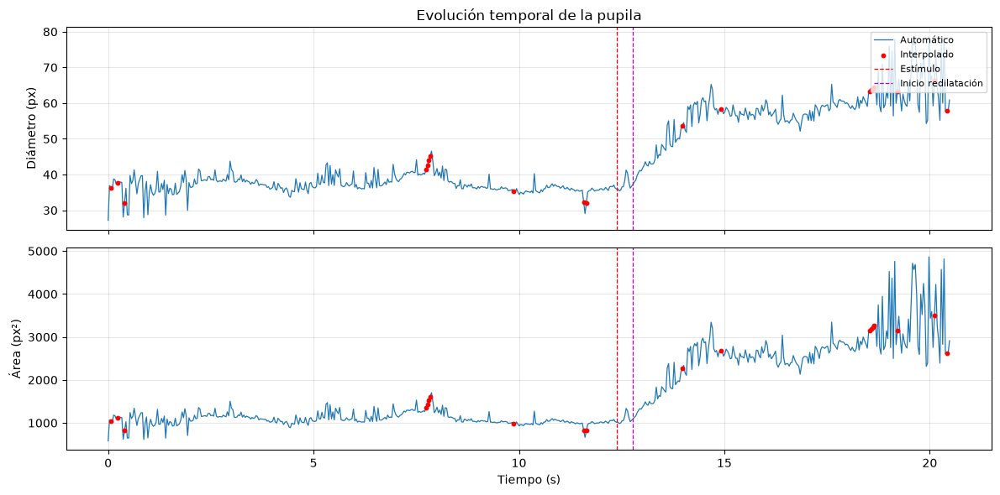

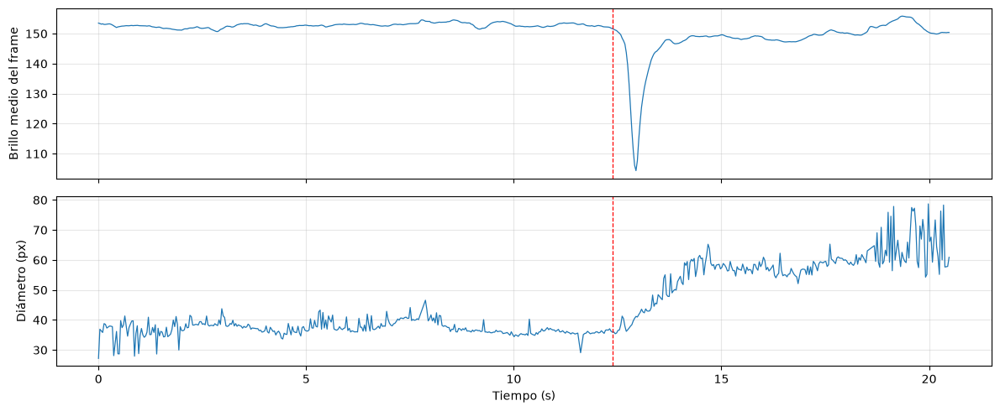

In [28]:
P, ev = m3.calcular_parametros(df, fps, cfg)
tabla_par = m3.parametros_a_tabla(P)
display(tabla_par)
graficar_curva(df, P, ev)
plt.show()

fig, axs = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
axs[0].plot(df["tiempo_s"], df["brillo_medio"], lw=0.9); axs[0].set_ylabel("Brillo medio del frame")
axs[1].plot(df["tiempo_s"], df["diametro_px"], lw=0.9); axs[1].set_ylabel("Diámetro (px)")
for ax in axs:
    if ev["i_estimulo"] is not None: ax.axvline(df["tiempo_s"].iloc[ev["i_estimulo"]], color="r", ls="--", lw=0.9)
    ax.grid(alpha=0.3)
axs[1].set_xlabel("Tiempo (s)"); plt.tight_layout(); plt.show()

**Cómo se calculan** (`pupila/modulo3.py`):
- **Estímulo:** frame del mayor salto de brillo medio del video (o `fisiologia.t_estimulo_s` del config).
- **Latencia:** primer frame desde el estímulo con 5 frames consecutivos por debajo de *línea base − 3σ* (base: 2 s previos). La latencia pupilar humana a un flash ronda 200–300 ms.
- **Amplitud:** área basal (mediana previa al estímulo) − área mínima de la serie suavizada.
- **Velocidad de constricción:** caída hasta el 90 % de la caída total / tiempo desde el inicio de la constricción.
- **Velocidad de redilatación:** del 10 % al 90 % de la recuperación posterior al mínimo; si la pupila no se recupera durante el registro queda en NaN.

Todo está en **píxeles**: si la cámara cambió de distancia entre tomas, los valores absolutos no son comparables.

### 3.6 Variabilidad entre registros

In [30]:
VIDEO_B = Path("data/Registro B_1.mov")
if VIDEO_B.exists():
    cfg_B = cargar_config("config.yaml", video_path=VIDEO_B, output_dir="resultados/B")
    # cfg_B["centro_pupila_inicial"] = [1390, 590]      # si la detección automática no acierta
    res_B = ejecutar_pipeline(cfg_B, guardar=False)
    tabla_trials, resumen_trials = m3.variabilidad_entre_registros([P, res_B["parametros"]], ["A", "B"])
    display(tabla_trials.round(3)); display(resumen_trials.round(3))
else:
    print("Poné otro registro en", VIDEO_B, "para comparar latencia/amplitud entre trials.")

Video: /Users/somi/Documents/PSIB/Guia_Imagenes_Biomed/PSIB_Guia_Imag_Biomed_Grupo15/proyecto_ojo/data/Registro B_1.mov
1920x1080 | 29.98 fps | 615 frames | 20.5 s
Centro pupilar inicial (automático): (650, 589)
  detección: confianza 78% (7/9 frames) | grupos candidatos (x, y, votos): [(649, 589, 7), (1393, 601, 6), (1433, 604, 3), (669, 568, 2)]
  frame 615/615
                        parametro       valor unidad
                     t_estimulo_s   12.375715      s
                   frame_estimulo  371.000000  frame
          t_inicio_constriccion_s         NaN      s
                      latencia_ms         NaN     ms
                diametro_basal_px   35.918087     px
               diametro_minimo_px   36.528825     px
             amplitud_diametro_px   -0.610737     px
                   area_basal_px2 1013.250000    px2
                  area_minima_px2 1048.000000    px2
                amplitud_area_px2  -34.750000    px2
                amplitud_area_pct   -3.429558      

,A,B
t_estimulo_s,12.376,12.376
frame_estimulo,371.000,371.000
t_inicio_constriccion_s,NaN,NaN
latencia_ms,NaN,NaN
diametro_basal_px,35.918,35.918
diametro_minimo_px,36.529,36.529
amplitud_diametro_px,-0.611,-0.611
area_basal_px2,1013.250,1013.250
area_minima_px2,1048.000,1048.000
amplitud_area_px2,-34.750,-34.750


,media,desvio,n,CV (%)
t_estimulo_s,12.376,0.0,2,0.0
frame_estimulo,371.000,0.0,2,0.0
t_inicio_constriccion_s,NaN,NaN,0,NaN
latencia_ms,NaN,NaN,0,NaN
diametro_basal_px,35.918,0.0,2,0.0
diametro_minimo_px,36.529,0.0,2,0.0
amplitud_diametro_px,-0.611,0.0,2,0.0
area_basal_px2,1013.250,0.0,2,0.0
area_minima_px2,1048.000,0.0,2,0.0
amplitud_area_px2,-34.750,0.0,2,0.0


### 3.7 Artefactos

- **Movimientos oculares/cabeza:** la pupila se sigue frame a frame y la ROI se recorta centrada en ella.
- **Reflejos del flash:** se detectan los píxeles muy brillantes cerca de la pupila, se dilatan y se rellenan (*inpainting*); además hay apertura morfológica y suavizado gaussiano en el seguimiento.
- **Pestañas/sombras:** Watershed con tres radios de marcador (se elige el de mayor contraste de borde) + apertura 11×11, cierre 21×21 y envolvente convexa.
- **Parpadeos/errores de segmentación:** frames con circularidad < umbral (o sin contorno) se marcan como inválidos y se **interpolan linealmente**. El umbral 0.89 se eligió observando un solo video: revisalo con otros registros.

# Módulo 4 — Compresión de la información

### 4.1 Huffman (sin pérdida)

In [31]:
res_h = {n: m4.evaluar_huffman(im) for n, im in {"ROI gris": roi_gray, "ROI RGB": roi_rgb}.items()}
display(pd.DataFrame({n: {k: v for k, v in r.items() if k != "reconstruida"} for n, r in res_h.items()}).T.round(4))

,bits,bits_originales,bytes,n_simbolos,ratio,reduccion_pct,identica
ROI gris,305792,332800,38224,237,1.088321,8.115385,True
ROI RGB,905637,998400,113205,213,1.102428,9.291166,True


*Nota:* los bits de Huffman **no incluyen** el costo de almacenar la tabla de códigos; la reducción real es algo menor.

### 4.2 RLE horizontal y vertical (sin pérdida)

,corridas,bytes,ratio,reduccion_pct,identica
horizontal,33718,168590,0.246752,-305.264423,True
vertical,34189,170945,0.243353,-310.925481,True


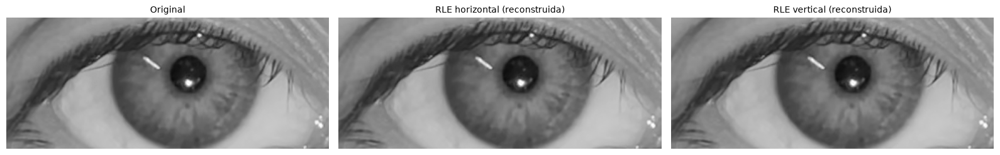

In [32]:
res_r = {d: m4.evaluar_rle(roi_gray, d, bytes_valor=1, bytes_longitud=4) for d in ("horizontal", "vertical")}
display(pd.DataFrame({d: {k: v for k, v in r.items() if k != "reconstruida"} for d, r in res_r.items()}).T.round(3))
mostrar([roi_gray, res_r["horizontal"]["reconstruida"], res_r["vertical"]["reconstruida"]],
        ["Original", "RLE horizontal (reconstruida)", "RLE vertical (reconstruida)"], figsize=(16, 4))

*Análisis (versión original):* la reconstrucción es exacta, pero el tamaño estimado (1 byte de valor + 4 de longitud por corrida) **supera** al original: una imagen natural tiene pocos píxeles consecutivos idénticos.
El recorrido horizontal es un poco menos malo que el vertical. (Con longitudes de 1 byte, `bytes_longitud=1`, la penalización sería menor.)

### 4.3 JPEG (con pérdida): Q = 90, 50, 10, 5

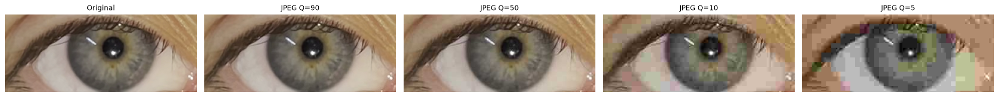

,Calidad JPEG,Tamaño JPEG (bytes),Tamaño PNG de referencia (bytes),Reducción respecto a PNG (%),Error absoluto medio
0,90,9656,65344,85.223,1.249
1,50,4389,65344,93.283,2.525
2,10,2103,65344,96.782,6.716
3,5,1674,65344,97.438,10.730


In [33]:
imgs_q, tabla_jpeg = m4.jpeg_rgb(roi_rgb, (90, 50, 10, 5))
mostrar([roi_rgb, *imgs_q.values()], ["Original"] + [f"JPEG Q={q}" for q in imgs_q], figsize=(20, 4))
display(tabla_jpeg.round(3))

### 4.4 Comparación: ratio de compresión, PSNR y SSIM (ROI en gris)

,Método,Tamaño (bytes),Ratio de compresión,Reducción (%),PSNR (dB),SSIM,Índice de bloques (rel. al original),Reconstrucción idéntica
0,Huffman,38224,1.0883,8.1154,inf,1.0000,1.0000,True
1,RLE horizontal,168590,0.2468,-305.2644,inf,1.0000,1.0000,True
2,RLE vertical,170945,0.2434,-310.9255,inf,1.0000,1.0000,True
3,JPEG Q=90,8407,4.9483,79.7909,45.9407,0.9926,1.1082,False
4,JPEG Q=50,3749,11.0963,90.9880,39.1147,0.9686,1.5272,False
5,JPEG Q=10,1581,26.3125,96.1995,31.3189,0.8442,3.2711,False
6,JPEG Q=5,1160,35.8621,97.2115,27.7741,0.7236,5.4060,False


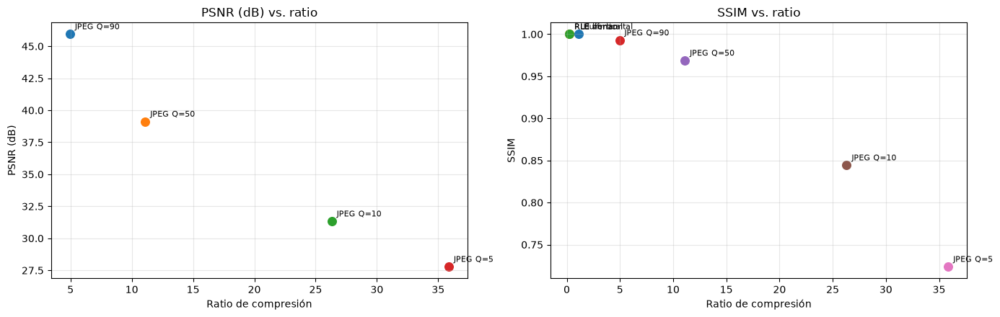

(Los métodos sin pérdida tienen PSNR = ∞ y no aparecen en el gráfico de PSNR.)


In [34]:
tabla_comp, recons = m4.comparar_compresion(roi_gray, calidades=(90, 50, 10, 5))
display(tabla_comp.round(4))

fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
for _, f in tabla_comp.iterrows():
    for ax, col in zip(axs, ["PSNR (dB)", "SSIM"]):
        if np.isfinite(f[col]):
            ax.scatter(f["Ratio de compresión"], f[col], s=70)
            ax.annotate(f["Método"], (f["Ratio de compresión"], f[col]), xytext=(5, 5), textcoords="offset points", fontsize=8)
for ax, col in zip(axs, ["PSNR (dB)", "SSIM"]):
    ax.set_xlabel("Ratio de compresión"); ax.set_ylabel(col); ax.grid(alpha=0.3); ax.set_title(f"{col} vs. ratio")
plt.tight_layout(); plt.show()
print("(Los métodos sin pérdida tienen PSNR = ∞ y no aparecen en el gráfico de PSNR.)")

### 4.5 Artefactos de bloque y zoom sobre la pupila

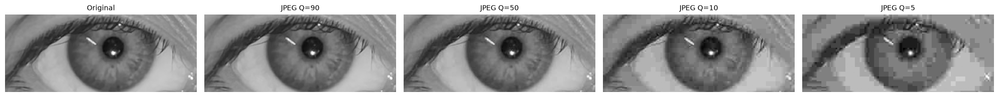

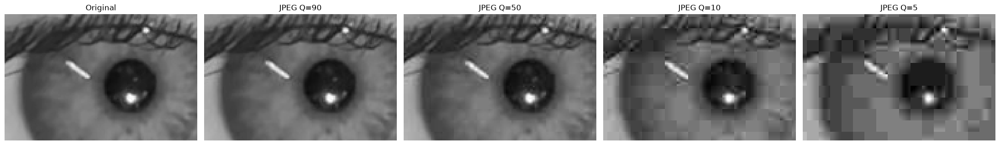

Índice de bloques relativo al original (1 = igual que el original; crece cuando aparecen discontinuidades en los bordes de los bloques 8x8):


Método,Huffman,RLE horizontal,RLE vertical,JPEG Q=90,JPEG Q=50,JPEG Q=10,JPEG Q=5
Índice de bloques (rel. al original),1.0,1.0,1.0,1.108,1.527,3.271,5.406


In [35]:
cal = (90, 50, 10, 5)
mostrar([roi_gray] + [recons[f"JPEG Q={q}"] for q in cal], ["Original"] + [f"JPEG Q={q}" for q in cal], figsize=(20, 4))

zw, zh = int(roi_gray.shape[1] * 0.42), int(roi_gray.shape[0] * 0.68)
x1 = int(np.clip(cx - zw // 2, 0, roi_gray.shape[1] - zw)); y1 = int(np.clip(cy - zh // 2, 0, roi_gray.shape[0] - zh))
zoom = lambda im: im[y1:y1 + zh, x1:x1 + zw]
fig, axs = plt.subplots(1, 5, figsize=(22, 4.5))
for ax, (n, im) in zip(axs, [("Original", roi_gray)] + [(f"JPEG Q={q}", recons[f"JPEG Q={q}"]) for q in cal]):
    ax.imshow(zoom(im), cmap="gray", vmin=0, vmax=255, interpolation="nearest"); ax.set_title(n); ax.axis("off")
plt.tight_layout(); plt.show()

print("Índice de bloques relativo al original (1 = igual que el original; crece cuando aparecen discontinuidades en los bordes de los bloques 8x8):")
display(tabla_comp[["Método", "Índice de bloques (rel. al original)"]].set_index("Método").round(3).T)

*Para responder:* ¿desde qué Q emergen los artefactos de bloque? (mirar el zoom y cómo crece el *índice de bloques* al bajar Q);
¿son más notorios en los bordes nítidos de la pupila o en regiones uniformes del iris/esclerótica? Completá con lo observado.

### 4.6 Compresión sobre la ROI segmentada (pupila aislada)

In [36]:
roi_seg = cv2.bitwise_and(roi_gray, roi_gray, mask=mask_pupila)
tabla_seg, _ = m4.comparar_compresion(roi_seg)
display(tabla_seg.round(4))

,Método,Tamaño (bytes),Ratio de compresión,Reducción (%),PSNR (dB),SSIM,Índice de bloques (rel. al original),Reconstrucción idéntica
0,Huffman,8710,4.7761,79.0625,inf,1.0000,1.0000,True
1,RLE horizontal,19020,2.1872,54.2788,inf,1.0000,1.0000,True
2,RLE vertical,20105,2.0691,51.6707,inf,1.0000,1.0000,True
3,JPEG Q=90,2807,14.8201,93.2524,48.7798,0.9958,1.0127,False
4,JPEG Q=50,1617,25.7267,96.1130,39.8101,0.9851,1.2913,False
5,JPEG Q=10,1058,39.3195,97.4567,34.9836,0.9653,2.2277,False
6,JPEG Q=5,951,43.7434,97.7139,28.6221,0.1745,3.0962,False


### 4.7 ¿La compresión JPEG cambia el diámetro pupilar estimado?

,Área (px²),Diámetro equivalente (px),Cambio diámetro (px),Cambio diámetro (%)
Imagen,,,,
Original,3878.5,70.273,0.000,0.000
Q=50,3092.5,62.749,-7.523,-10.706
Q=10,3360.0,65.407,-4.866,-6.924


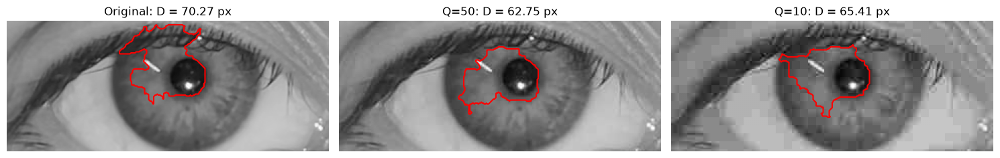

In [37]:
tabla_diam, masks_q, imgs_q_diam = m4.efecto_jpeg_en_diametro(roi_gray, cx, cy, calidades=(50, 10))
display(tabla_diam.round(3))
fig, axs = plt.subplots(1, len(imgs_q_diam), figsize=(5 * len(imgs_q_diam), 4))
for ax, n in zip(axs, imgs_q_diam):
    ax.imshow(imgs_q_diam[n], cmap="gray", vmin=0, vmax=255); ax.contour(masks_q[n] > 0, colors="r", linewidths=1.5)
    ax.set_title(f"{n}: D = {tabla_diam.loc[n, 'Diámetro equivalente (px)']:.2f} px"); ax.axis("off")
plt.tight_layout(); plt.show()

In [38]:
res = ejecutar_pipeline(cfg, df_previo=df, progreso=False)
print("Archivos:", {k: str(v) for k, v in res["rutas"].items()})
display(pd.read_csv(res["rutas"]["resultados"]).head())
if res["avisos"]:
    print("Avisos del reporte:", res["avisos"])

Archivos: {'resultados': '/Users/somi/Documents/PSIB/Guia_Imagenes_Biomed/PSIB_Guia_Imag_Biomed_Grupo15/proyecto_ojo/resultados/resultados.csv'}


,frame,tiempo_s,area_px2,diametro_px,interpolado,circularidad,centro_x_px,centro_y_px,brillo_medio,t_estimulo_s,...,velocidad_constriccion_diam_px_s,velocidad_constriccion_area_px2_s,duracion_constriccion_s,t_inicio_redilatacion_s,velocidad_redilatacion_diam_px_s,velocidad_redilatacion_area_px2_s,fps,n_frames,duracion_s,frames_interpolados_pct
0,0,0.000000,580.5,27.186680,False,0.891246,671,557,153.510465,12.375715,...,NaN,NaN,NaN,12.776008,13.059665,299.331875,29.978065,615.0,20.515,3.089431
1,1,0.033358,1070.0,36.910247,False,0.929695,670,560,153.368875,12.375715,...,NaN,NaN,NaN,12.776008,13.059665,299.331875,29.978065,615.0,20.515,3.089431
2,2,0.066715,1039.0,36.367587,True,0.884434,668,559,153.161265,12.375715,...,NaN,NaN,NaN,12.776008,13.059665,299.331875,29.978065,615.0,20.515,3.089431
3,3,0.100073,1008.0,35.824928,False,0.925668,668,561,153.266734,12.375715,...,NaN,NaN,NaN,12.776008,13.059665,299.331875,29.978065,615.0,20.515,3.089431
4,4,0.133431,1181.0,38.777518,False,0.945449,667,558,153.075183,12.375715,...,NaN,NaN,NaN,12.776008,13.059665,299.331875,29.978065,615.0,20.515,3.089431
